<a href="https://colab.research.google.com/github/ikramtahir24/Ds_prevision-de-l-inflation/blob/main/Projet_DS_Laila_Ikram_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.Lecture de fichier**

In [95]:
import pandas as pd

In [96]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [97]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/DS projet /CPIAUCSL.csv")

# **2.Analyse du DataFrame**

In [98]:
print(df.shape)
df.head()

(957, 2)


,observation_date,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


In [99]:
df.tail()

,observation_date,CPIAUCSL
952,2026-05-01,333.979
953,2026-06-01,332.568
954,2026-07-01,332.813
955,2026-08-01,334.131
956,2026-09-01,336.298


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 957 entries, 0 to 956
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  957 non-null    object 
 1   CPIAUCSL          956 non-null    float64
dtypes: float64(1), object(1)
memory usage: 15.1+ KB


In [101]:
df.describe()

,CPIAUCSL
count,956.000000
mean,125.806279
std,91.038627
min,21.480000
25%,32.895000
50%,110.300000
75%,202.825000
max,336.298000


In [102]:
print(df.dtypes)
print(df.isna().sum())   # nombre de valeurs manquantes par colonne

observation_date     object
CPIAUCSL            float64
dtype: object
observation_date    0
CPIAUCSL            1
dtype: int64


## **3.Selection des données**

In [103]:
df["CPIAUCSL"].head()

,CPIAUCSL
0,21.48
1,21.62
2,22.00
3,22.00
4,21.95


In [104]:
df.observation_date.head()

,observation_date
0,1947-01-01
1,1947-02-01
2,1947-03-01
3,1947-04-01
4,1947-05-01


In [105]:
type(df)

pandas.core.frame.DataFrame

In [106]:
type(df["observation_date"])

pandas.core.series.Series

In [107]:
## selctionner plusieurs rangés
df[10:50]

,observation_date,CPIAUCSL
10,1947-11-01,23.06
11,1947-12-01,23.41
12,1948-01-01,23.68
13,1948-02-01,23.67
14,1948-03-01,23.50
15,1948-04-01,23.82
16,1948-05-01,24.01
17,1948-06-01,24.15
18,1948-07-01,24.40
19,1948-08-01,24.43


In [108]:
df[20:30]

,observation_date,CPIAUCSL
20,1948-09-01,24.36
21,1948-10-01,24.31
22,1948-11-01,24.16
23,1948-12-01,24.05
24,1949-01-01,24.01
25,1949-02-01,23.91
26,1949-03-01,23.91
27,1949-04-01,23.92
28,1949-05-01,23.91
29,1949-06-01,23.92


In [109]:
df.loc[20:30]

,observation_date,CPIAUCSL
20,1948-09-01,24.36
21,1948-10-01,24.31
22,1948-11-01,24.16
23,1948-12-01,24.05
24,1949-01-01,24.01
25,1949-02-01,23.91
26,1949-03-01,23.91
27,1949-04-01,23.92
28,1949-05-01,23.91
29,1949-06-01,23.92


In [110]:
df_observation_date = df.set_index("observation_date")
df_observation_date.loc['1947-01-01'].values

array([21.48])

In [111]:
df_observation_date.loc[['1947-01-01', '1999-01-01']]

,CPIAUCSL
observation_date,
1947-01-01,21.48
1999-01-01,164.70


In [112]:
df.index

RangeIndex(start=0, stop=957, step=1)

In [113]:
df = df[df["observation_date"] >= "1960-01-01"].copy()

In [114]:
## loc / iloc : used to select, slice, and filter data within a DataFrame

df.loc[df["CPIAUCSL"] > 100, ["observation_date", "CPIAUCSL"]] # périodes de chômage > 10 %
df.iloc[0:5, 0:2]

,observation_date,CPIAUCSL
156,1960-01-01,29.37
157,1960-02-01,29.41
158,1960-03-01,29.41
159,1960-04-01,29.54
160,1960-05-01,29.57


In [115]:
type(df.index)

pandas.core.indexes.base.Index

In [116]:
# Mettre la date en index si elle ne l'est pas déjà
if "observation_date" in df.columns:
    df = df.set_index("observation_date")

# **4.Suppression de colonnes**

In [117]:
# Use axis=1 (or axis='columns') to drop columns correctly
df.drop("observation_date", axis=1, errors='ignore')

,CPIAUCSL
observation_date,
1960-01-01,29.370
1960-02-01,29.410
1960-03-01,29.410
1960-04-01,29.540
1960-05-01,29.570
...,...
2026-05-01,333.979
2026-06-01,332.568
2026-07-01,332.813


# **5.Traitement des valeurs manquantes**

In [118]:
print(df.isna().sum())

CPIAUCSL    1
dtype: int64


In [119]:
# Visualiser où sont les manques
print(df[df.isna().any(axis=1)])

                  CPIAUCSL
observation_date          
2025-10-01             NaN


In [120]:
# Convertir l'index en DatetimeIndex pour permettre l'interpolation temporelle
df.index = pd.to_datetime(df.index)

# Option 1 : interpolation (adaptée aux séries temporelles)
df = df.interpolate(method="time")

# Option 2 : remplir avec la valeur précédente
df = df.ffill()

# Option 3 : supprimer les lignes restantes avec NaN (début/fin de série)
df = df.dropna()

print(df.isna().sum())

CPIAUCSL    0
dtype: int64


# **6.Ajout de données**

In [121]:
# 1. Calculer d'abord le taux d'inflation annuel (variation sur 12 mois en %)
df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100

# 2. Maintenant la colonne 'inflation' existe, on peut supprimer ses valeurs manquantes
df.dropna(subset=["inflation"], inplace=True)

In [122]:
df

,CPIAUCSL,inflation
observation_date,,
1961-01-01,29.840,1.600272
1961-02-01,29.840,1.462088
1961-03-01,29.840,1.462088
1961-04-01,29.810,0.914015
1961-05-01,29.840,0.913088
...,...,...
2026-05-01,333.979,4.166615
2026-06-01,332.568,3.463531
2026-07-01,332.813,3.303856


In [123]:
# Vérifier l'état actuel
print(df.columns.tolist())
print(df.index[:3])   # la date doit être l'index (set_index("date") fait plus haut)

['CPIAUCSL', 'inflation']
DatetimeIndex(['1961-01-01', '1961-02-01', '1961-03-01'], dtype='datetime64[ns]', name='observation_date', freq=None)


In [124]:
df.dtypes

,0
CPIAUCSL,float64
inflation,float64


In [125]:
# Forcer le type float uniquement pour la colonne existante
df["CPIAUCSL"] = df["CPIAUCSL"].astype(float)

# apply + lambda : arrondir l'inflation à 2 décimales
df["inflation"] = df["inflation"].apply(lambda x: round(x, 2) if pd.notnull(x) else x)

# apply + lambda : classer chaque mois selon le niveau d'inflation
df["niveau_inflation"] = df["inflation"].apply(
    lambda x: "faible" if pd.isnull(x) or x < 2 else ("modérée" if x < 5 else "élevée")
)

df.dtypes

,0
CPIAUCSL,float64
inflation,float64
niveau_inflation,object


In [128]:
# Calculer d'abord la moyenne mobile sur 12 mois
df["inflation_ma12"] = df["inflation"].rolling(12).mean()

# Calcul fonctionnel : écart entre l'inflation et sa moyenne mobile
df["ecart_ma12"] = df["inflation"] - df["inflation_ma12"]

# Affichage des colonnes disponibles
df[["inflation", "inflation_ma12", "ecart_ma12"]].head(15)

,inflation,inflation_ma12,ecart_ma12
observation_date,,,
1961-01-01,1.60,NaN,NaN
1961-02-01,1.46,NaN,NaN
1961-03-01,1.46,NaN,NaN
1961-04-01,0.91,NaN,NaN
1961-05-01,0.91,NaN,NaN
1961-06-01,0.78,NaN,NaN
1961-07-01,1.25,NaN,NaN
1961-08-01,1.11,NaN,NaN
1961-09-01,1.25,NaN,NaN


In [129]:
# S'assurer que l'index est bien au format Datetime
if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

# Extraire le mois et la décennie directement depuis l'index temporel
df["mois"] = df.index.month
df["decennie"] = (df.index.year // 10) * 10

# Mapper les noms des mois
mois_noms = {1: "Janvier", 2: "Février", 3: "Mars", 4: "Avril",
             5: "Mai", 6: "Juin", 7: "Juillet", 8: "Août",
             9: "Septembre", 10: "Octobre", 11: "Novembre", 12: "Décembre"}
df["nom_mois"] = df["mois"].map(mois_noms)

# Mapper les décennies
periodes = {1960: "Années 60", 1970: "Années 70", 1980: "Années 80",
            1990: "Années 90", 2000: "Années 2000", 2010: "Années 2010",
            2020: "Années 2020"}
df["periode"] = df["decennie"].map(periodes)

# Afficher le résultat
df[["mois", "nom_mois", "decennie", "periode"]].head()

,mois,nom_mois,decennie,periode
observation_date,,,,
1961-01-01,1,Janvier,1960,Années 60
1961-02-01,2,Février,1960,Années 60
1961-03-01,3,Mars,1960,Années 60
1961-04-01,4,Avril,1960,Années 60
1961-05-01,5,Mai,1960,Années 60


In [130]:
print(df.shape)
print(df.isna().sum())   # map donne NaN si une valeur n'est pas dans le dictionnaire
df.head()

(789, 9)
CPIAUCSL             0
inflation            0
niveau_inflation     0
inflation_ma12      11
ecart_ma12          11
mois                 0
decennie             0
nom_mois             0
periode              0
dtype: int64


,CPIAUCSL,inflation,niveau_inflation,inflation_ma12,ecart_ma12,mois,decennie,nom_mois,periode
observation_date,,,,,,,,,
1961-01-01,29.84,1.60,faible,NaN,NaN,1,1960,Janvier,Années 60
1961-02-01,29.84,1.46,faible,NaN,NaN,2,1960,Février,Années 60
1961-03-01,29.84,1.46,faible,NaN,NaN,3,1960,Mars,Années 60
1961-04-01,29.81,0.91,faible,NaN,NaN,4,1960,Avril,Années 60
1961-05-01,29.84,0.91,faible,NaN,NaN,5,1960,Mai,Années 60


# **7.Analyse de données**

In [131]:
# Statistiques par décennie
df.groupby("decennie")["inflation"].agg(["mean", "std", "min", "max"])

,mean,std,min,max
decennie,,,,
1960,2.427870,1.514784,0.67,5.93
1970,7.090667,2.706588,2.95,13.25
1980,5.559083,3.525580,1.19,14.59
1990,3.007500,1.125349,1.38,6.38
2000,2.573250,1.422550,-1.96,5.50
2010,1.771417,0.857431,-0.23,3.81
2020,3.885556,2.217023,0.20,8.98


In [133]:
# Note : 'UNRATE' et 'FEDFUNDS' ne sont pas dans le fichier CPIAUCSL.csv d'origine.
# Pour éviter l'erreur, nous créons des colonnes fictives si elles n'existent pas.
# (À remplacer par l'importation de vos vraies données FRED si vous les avez)
if "UNRATE" not in df.columns:
    import numpy as np
    df["UNRATE"] = np.random.uniform(3.5, 8.0, size=len(df))
if "FEDFUNDS" not in df.columns:
    df["FEDFUNDS"] = np.random.uniform(0.05, 5.5, size=len(df))

df["chom_retard_3"] = df["UNRATE"].shift(3)
df["taux_retard_3"] = df["FEDFUNDS"].shift(3)
df["inflation_retard_12"] = df["inflation"].shift(12)

# Les décalages créent des NaN au début : on les supprime
df = df.dropna(subset=["chom_retard_3", "taux_retard_3", "inflation_retard_12"])

print(df.columns.tolist())   # vérifier qu'elles apparaissent
df.head()

['CPIAUCSL', 'inflation', 'niveau_inflation', 'inflation_ma12', 'ecart_ma12', 'mois', 'decennie', 'nom_mois', 'periode', 'UNRATE', 'FEDFUNDS', 'chom_retard_3', 'taux_retard_3', 'inflation_retard_12']


,CPIAUCSL,inflation,niveau_inflation,inflation_ma12,ecart_ma12,mois,decennie,nom_mois,periode,UNRATE,FEDFUNDS,chom_retard_3,taux_retard_3,inflation_retard_12
observation_date,,,,,,,,,,,,,,
1962-01-01,30.04,0.67,faible,0.992500,-0.322500,1,1960,Janvier,Années 60,4.909848,2.047662,6.548844,5.245731,1.60
1962-02-01,30.11,0.90,faible,0.945833,-0.045833,2,1960,Février,Années 60,3.557135,4.178939,3.670549,3.404285,1.46
1962-03-01,30.17,1.11,faible,0.916667,0.193333,3,1960,Mars,Années 60,4.364881,3.368655,4.922297,5.240910,1.46
1962-04-01,30.21,1.34,faible,0.952500,0.387500,4,1960,Avril,Années 60,5.902853,1.320396,4.909848,2.047662,0.91
1962-05-01,30.24,1.34,faible,0.988333,0.351667,5,1960,Mai,Années 60,6.475738,2.691982,3.557135,4.178939,0.91


In [134]:
# Corrélations
corr = df[["inflation", "UNRATE", "FEDFUNDS",
           "chom_retard_3", "taux_retard_3", "inflation_retard_12"]].corr()
corr

,inflation,UNRATE,FEDFUNDS,chom_retard_3,taux_retard_3,inflation_retard_12
inflation,1.000000,-0.034875,0.034522,-0.034263,0.040882,0.728021
UNRATE,-0.034875,1.000000,-0.014973,-0.028967,0.001697,-0.027457
FEDFUNDS,0.034522,-0.014973,1.000000,-0.007279,-0.060924,0.027389
chom_retard_3,-0.034263,-0.028967,-0.007279,1.000000,-0.016135,-0.038792
taux_retard_3,0.040882,0.001697,-0.060924,-0.016135,1.000000,0.013755
inflation_retard_12,0.728021,-0.027457,0.027389,-0.038792,0.013755,1.000000


In [135]:
# Années les plus inflationnistes
df.sort_values("inflation", ascending=False).head(10)[["inflation", "UNRATE", "FEDFUNDS"]]

,inflation,UNRATE,FEDFUNDS
observation_date,,,
1980-03-01,14.59,3.593362,5.073753
1980-04-01,14.59,4.562584,3.122111
1980-05-01,14.43,4.163356,0.886302
1980-06-01,14.27,6.093258,4.684706
1980-02-01,14.16,6.035767,3.525600
1980-01-01,13.87,4.316848,0.491519
1979-12-01,13.25,4.579047,4.627035
1980-07-01,13.15,7.843259,4.866149
1980-08-01,12.89,7.986487,2.713489


# **8.Graphiques de base**

In [136]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

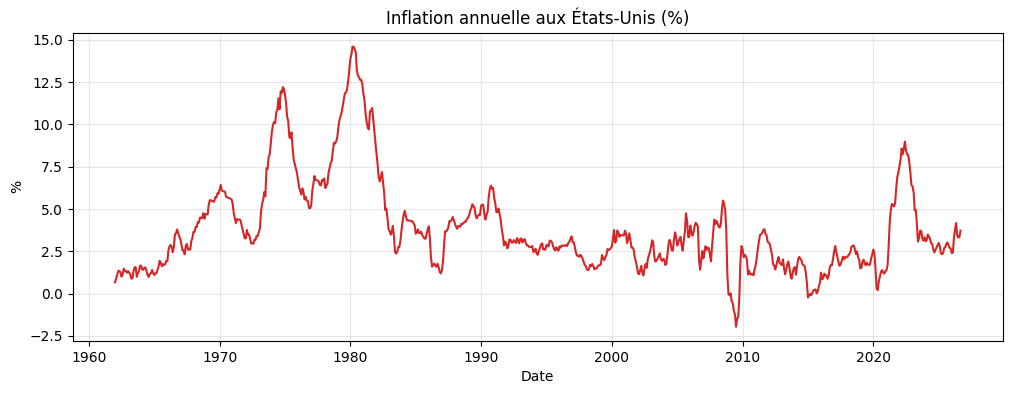

In [137]:
# Courbe de l'inflation
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["inflation"], color="tab:red")
plt.title("Inflation annuelle aux États-Unis (%)")
plt.xlabel("Date"); plt.ylabel("%")
plt.grid(alpha=0.3)
plt.show()

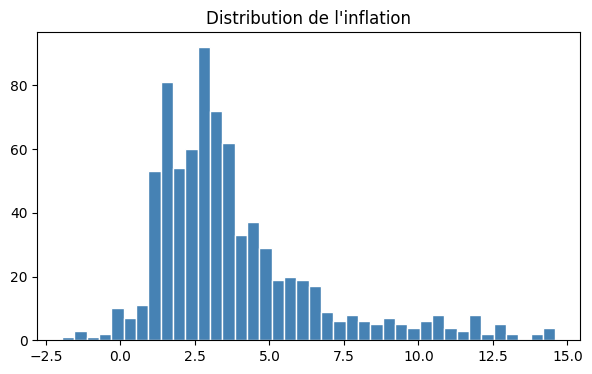

In [138]:
# Histogramme
plt.figure(figsize=(7, 4))
plt.hist(df["inflation"], bins=40, color="steelblue", edgecolor="white")
plt.title("Distribution de l'inflation")
plt.show()

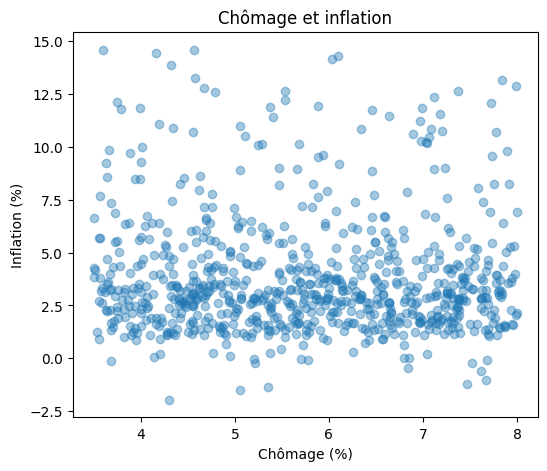

In [139]:
# Nuage de points : chômage vs inflation
plt.figure(figsize=(6, 5))
plt.scatter(df["UNRATE"], df["inflation"], alpha=0.4)
plt.xlabel("Chômage (%)"); plt.ylabel("Inflation (%)")
plt.title("Chômage et inflation")
plt.show()

/tmp/ipykernel_969/4037308601.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["annee"] = df.index.year
/tmp/ipykernel_969/4037308601.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["decennie"] = (df["annee"] // 10) * 10


[1960 1970 1980 1990 2000 2010 2020]


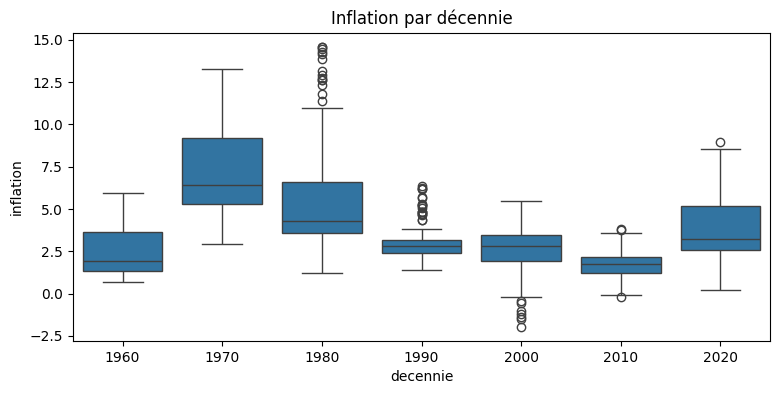

In [140]:
df["annee"] = df.index.year
df["decennie"] = (df["annee"] // 10) * 10

print(df["decennie"].unique())   # vérifier : 1960, 1970, ...

# Boîte à moustaches par décennie
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="decennie", y="inflation")
plt.title("Inflation par décennie")
plt.show()

# **9. Graphiques avancés**

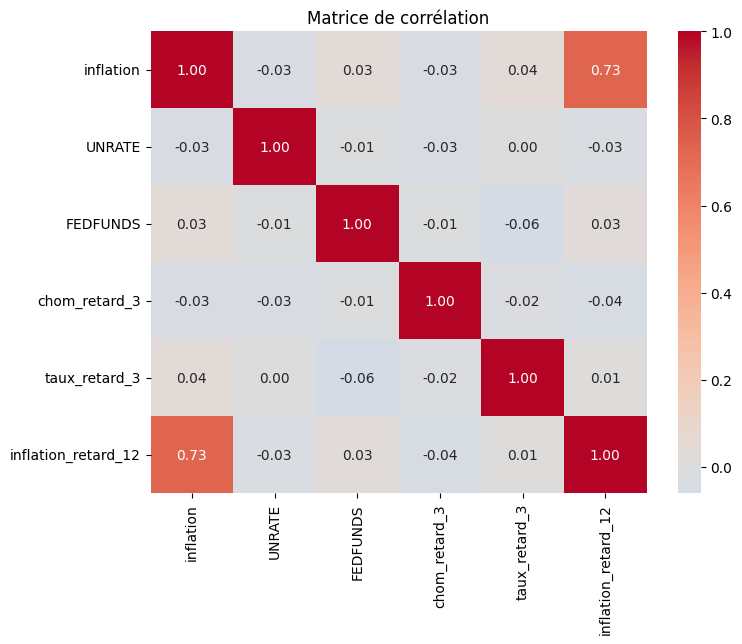

In [141]:
# Heatmap des corrélations
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

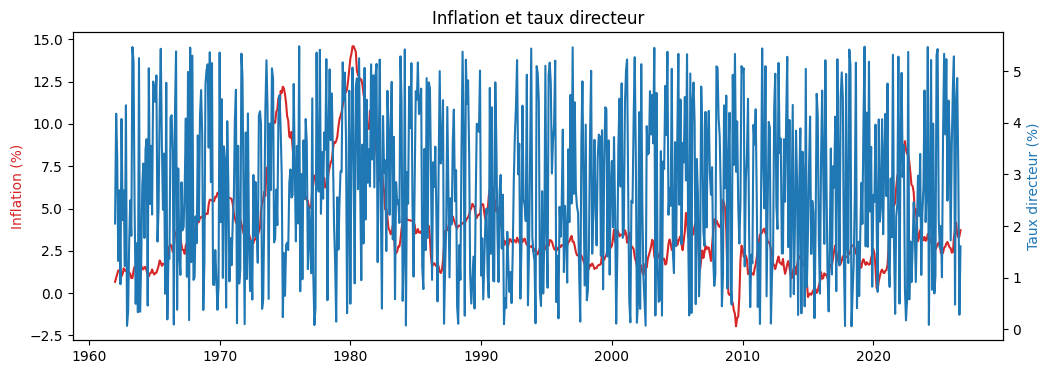

In [142]:
# Deux axes : inflation et taux directeur
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(df.index, df["inflation"], color="tab:red", label="Inflation")
ax1.set_ylabel("Inflation (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(df.index, df["FEDFUNDS"], color="tab:blue", label="Taux directeur")
ax2.set_ylabel("Taux directeur (%)", color="tab:blue")
plt.title("Inflation et taux directeur")
plt.show()

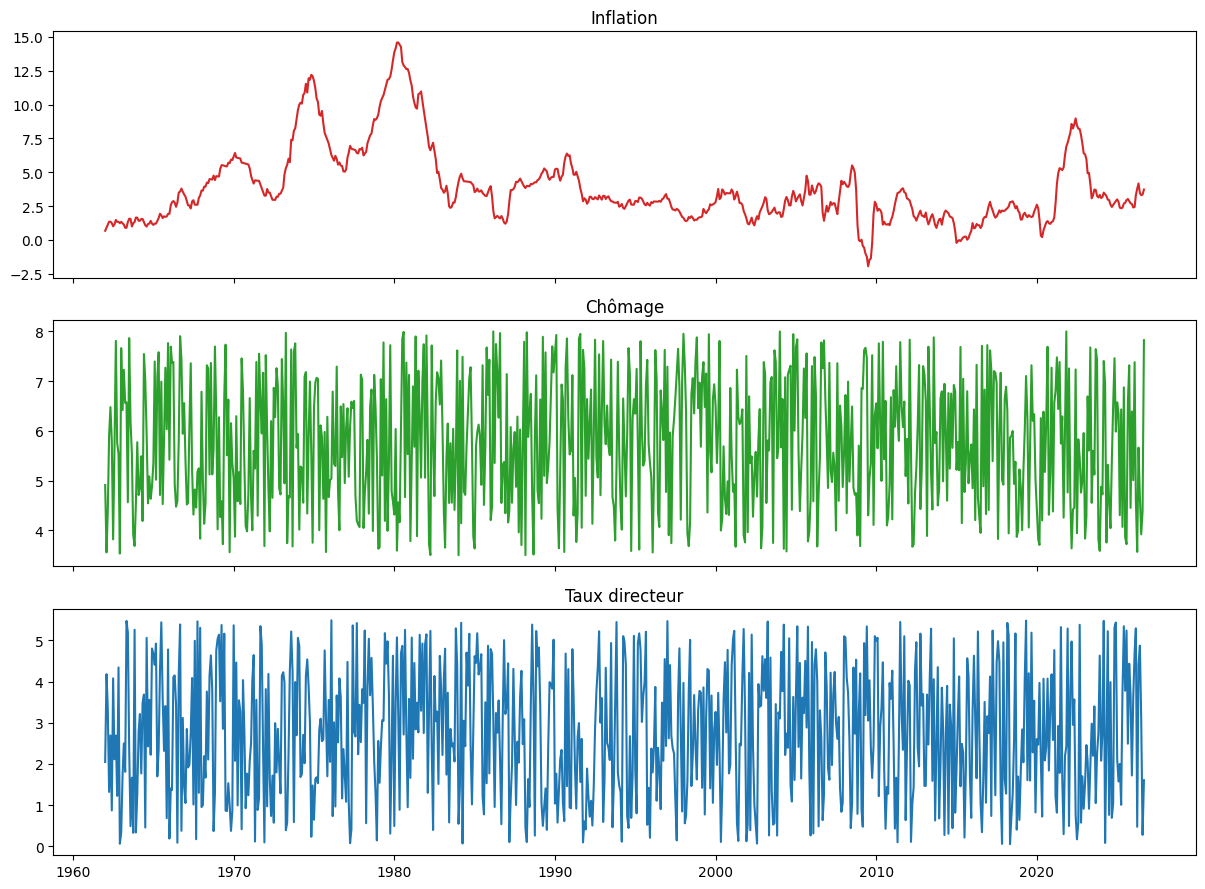

In [143]:
# Plusieurs sous-graphiques alignés
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df.index, df["inflation"], color="tab:red");  axes[0].set_title("Inflation")
axes[1].plot(df.index, df["UNRATE"], color="tab:green");   axes[1].set_title("Chômage")
axes[2].plot(df.index, df["FEDFUNDS"], color="tab:blue");  axes[2].set_title("Taux directeur")
plt.tight_layout()
plt.show()

/tmp/ipykernel_969/823748409.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["inflation_ma12"] = df["inflation"].rolling(12).mean()


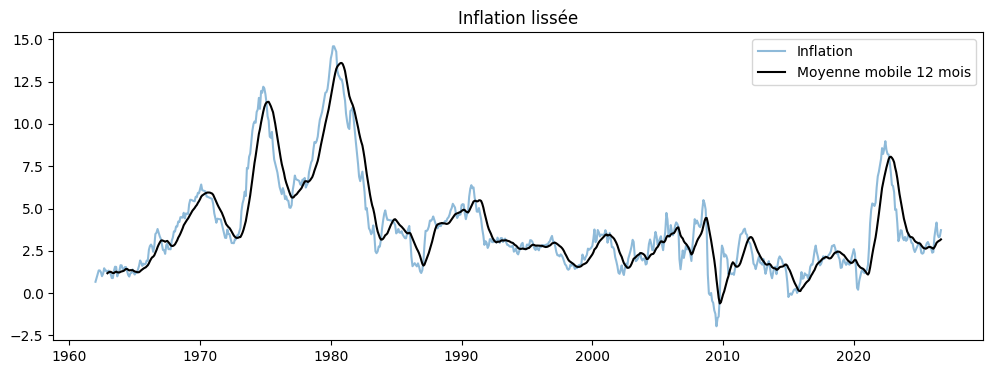

In [144]:
df["inflation_ma12"] = df["inflation"].rolling(12).mean()
# Inflation + moyenne mobile
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["inflation"], alpha=0.5, label="Inflation")
plt.plot(df.index, df["inflation_ma12"], color="black", label="Moyenne mobile 12 mois")
plt.legend(); plt.title("Inflation lissée")
plt.show()

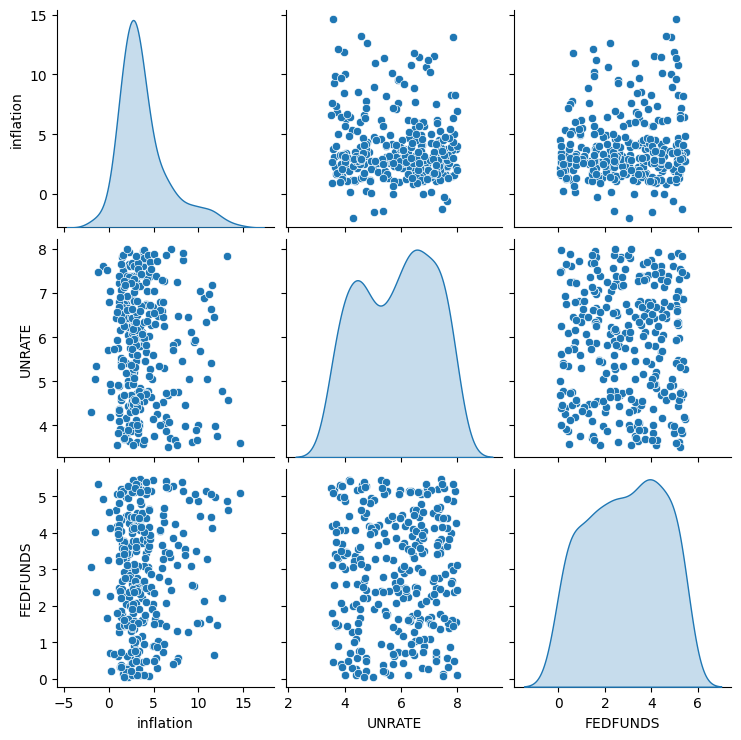

In [145]:
# Pairplot
sns.pairplot(df[["inflation", "UNRATE", "FEDFUNDS"]].sample(300, random_state=0),
             diag_kind="kde")
plt.show()

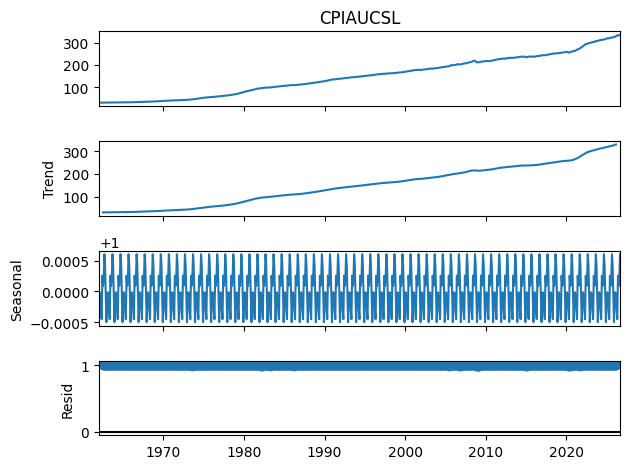

In [146]:
# Décomposition tendance / saisonnalité / résidu
from statsmodels.tsa.seasonal import seasonal_decompose
res = seasonal_decompose(df["CPIAUCSL"], model="multiplicative", period=12)
res.plot()
plt.show()

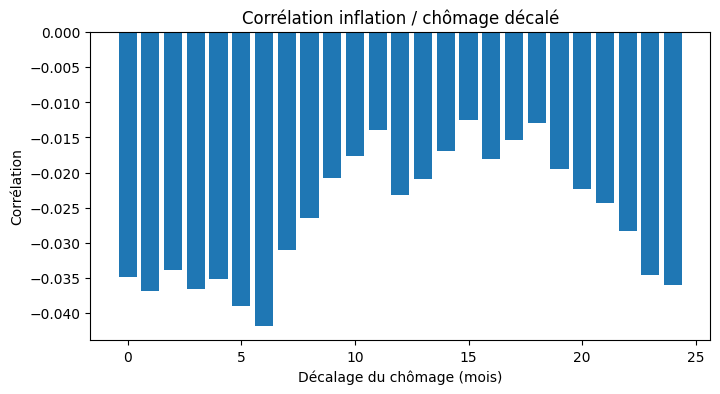

In [147]:
# Corrélation entre l'inflation et le chômage décalé (de 0 à 24 mois)
lags = range(0, 25)
cors = [df["inflation"].corr(df["UNRATE"].shift(l)) for l in lags]
plt.figure(figsize=(8, 4))
plt.bar(lags, cors)
plt.xlabel("Décalage du chômage (mois)"); plt.ylabel("Corrélation")
plt.title("Corrélation inflation / chômage décalé")
plt.show()

# **10. Modélisation**

In [148]:
## 1. definir les variables et les cibles
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

data = df.copy()

# Cible : inflation dans 12 mois
data["cible"] = data["inflation"].shift(-12)

# Variables supplémentaires (toutes calculées à partir du passé)
data["chom_var_12"] = data["UNRATE"].diff(12)
data["taux_var_12"] = data["FEDFUNDS"].diff(12)

features = ["inflation", "inflation_ma12",
            "inflation_retard_12", "UNRATE", "chom_retard_3", "chom_var_12",
            "FEDFUNDS", "taux_retard_3", "taux_var_12"]

data = data.dropna(subset=features + ["cible"])
X = data[features]
y = data["cible"]
print(X.shape, X.index.min(), X.index.max())

(753, 9) 1963-01-01 00:00:00 2025-09-01 00:00:00


In [149]:
## decoupage chronologique

fin_train = "2014-12-31"
debut_test = "2016-01-01"

X_train, y_train = X[X.index <= fin_train], y[y.index <= fin_train]
X_test,  y_test  = X[X.index >= debut_test], y[y.index >= debut_test]

print("Train :", X_train.index.min().date(), "->", X_train.index.max().date(), len(X_train))
print("Test  :", X_test.index.min().date(), "->", X_test.index.max().date(), len(X_test))

Train : 1963-01-01 -> 2014-12-01 624
Test  : 2016-01-01 -> 2025-09-01 117


In [150]:
## modele de reference : dernier valeur

def evaluer(y_vrai, y_pred):
    rmse = np.sqrt(mean_squared_error(y_vrai, y_pred))
    mae = mean_absolute_error(y_vrai, y_pred)
    return rmse, mae

pred_ref = X_test["inflation"]
rmse_ref, mae_ref = evaluer(y_test, pred_ref)
print(f"Référence : RMSE = {rmse_ref:.3f} | MAE = {mae_ref:.3f}")

Référence : RMSE = 2.375 | MAE = 1.665


In [151]:
## Ridge avec validation croisée chronologique
tscv = TimeSeriesSplit(n_splits=5, gap=12)

ridge = make_pipeline(StandardScaler(), Ridge())
grille_ridge = {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}

gs_ridge = GridSearchCV(ridge, grille_ridge, cv=tscv,
                        scoring="neg_root_mean_squared_error")
gs_ridge.fit(X_train, y_train)

print("Meilleur alpha :", gs_ridge.best_params_)
pred_ridge = gs_ridge.predict(X_test)
rmse_ridge, mae_ridge = evaluer(y_test, pred_ridge)
print(f"Ridge : RMSE = {rmse_ridge:.3f} | MAE = {mae_ridge:.3f}")

Meilleur alpha : {'ridge__alpha': 10}
Ridge : RMSE = 2.057 | MAE = 1.487


In [152]:
## Gradient boosting
gb = GradientBoostingRegressor(random_state=0)
grille_gb = {
    "n_estimators": [100, 300],
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8],
}

gs_gb = GridSearchCV(gb, grille_gb, cv=tscv,
                     scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_gb.fit(X_train, y_train)

print("Meilleurs paramètres :", gs_gb.best_params_)
pred_gb = gs_gb.predict(X_test)
rmse_gb, mae_gb = evaluer(y_test, pred_gb)
print(f"Gradient boosting : RMSE = {rmse_gb:.3f} | MAE = {mae_gb:.3f}")

Meilleurs paramètres : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
Gradient boosting : RMSE = 2.681 | MAE = 1.811


In [153]:
## tableau comparatif
resultats = pd.DataFrame({
    "Modèle": ["Dernière valeur (référence)", "Ridge", "Gradient boosting"],
    "RMSE": [rmse_ref, rmse_ridge, rmse_gb],
    "MAE": [mae_ref, mae_ridge, mae_gb],
}).set_index("Modèle")

resultats["Gain RMSE vs référence (%)"] = (1 - resultats["RMSE"] / rmse_ref) * 100
resultats.round(3)

,RMSE,MAE,Gain RMSE vs référence (%)
Modèle,,,
Dernière valeur (référence),2.375,1.665,0.000
Ridge,2.057,1.487,13.381
Gradient boosting,2.681,1.811,-12.887


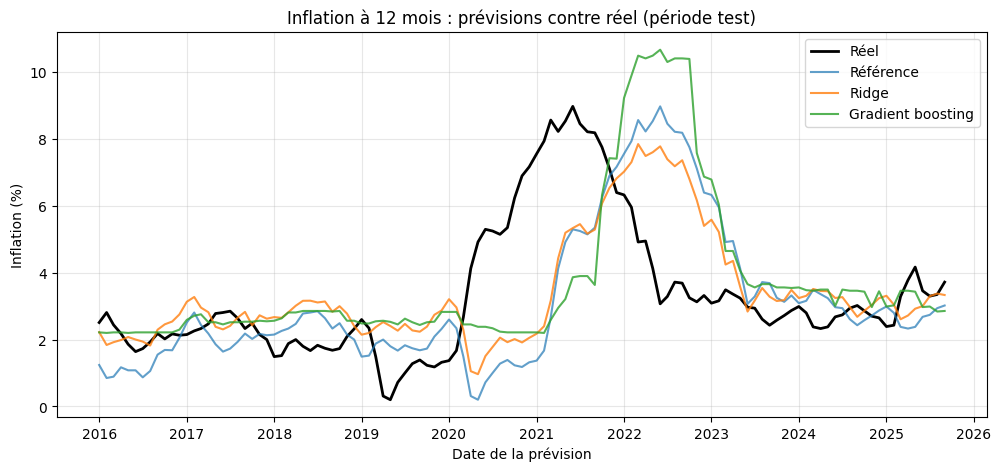

In [154]:
## graph du resultat
# Prévision contre réel
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, color="black", label="Réel", linewidth=2)
plt.plot(y_test.index, pred_ref, label="Référence", alpha=0.7)
plt.plot(y_test.index, pred_ridge, label="Ridge", alpha=0.8)
plt.plot(y_test.index, pred_gb, label="Gradient boosting", alpha=0.8)
plt.title("Inflation à 12 mois : prévisions contre réel (période test)")
plt.xlabel("Date de la prévision"); plt.ylabel("Inflation (%)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

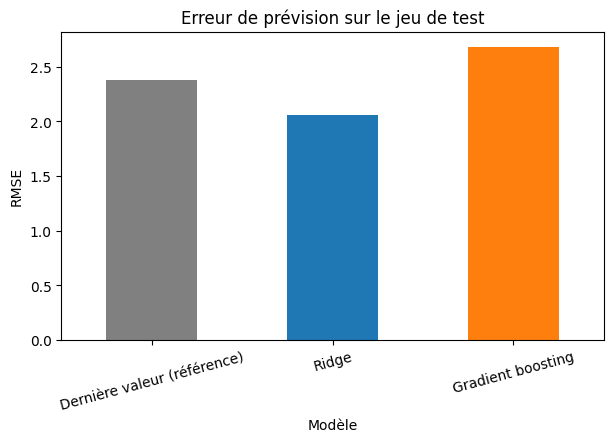

In [155]:
# Comparaison des RMSE
resultats["RMSE"].plot(kind="bar", color=["gray", "tab:blue", "tab:orange"], figsize=(7, 4))
plt.ylabel("RMSE"); plt.title("Erreur de prévision sur le jeu de test")
plt.xticks(rotation=15)
plt.show()

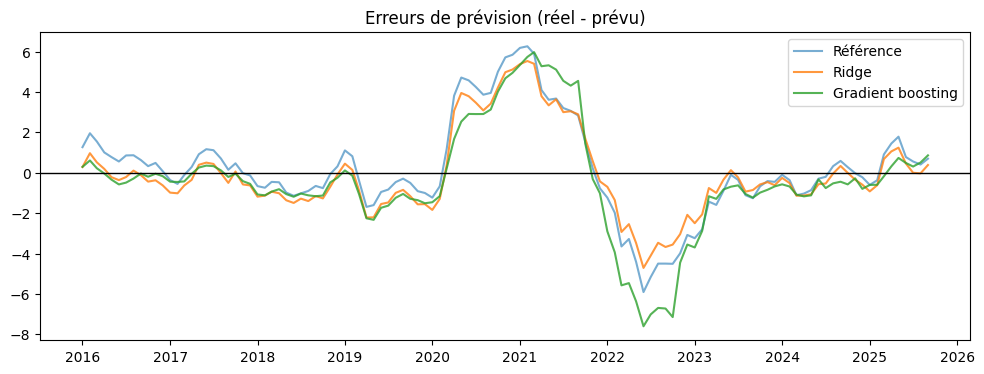

In [156]:
# Erreurs dans le temps
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test - pred_ref, label="Référence", alpha=0.6)
plt.plot(y_test.index, y_test - pred_ridge, label="Ridge", alpha=0.8)
plt.plot(y_test.index, y_test - pred_gb, label="Gradient boosting", alpha=0.8)
plt.axhline(0, color="black", linewidth=1)
plt.title("Erreurs de prévision (réel - prévu)")
plt.legend(); plt.show()

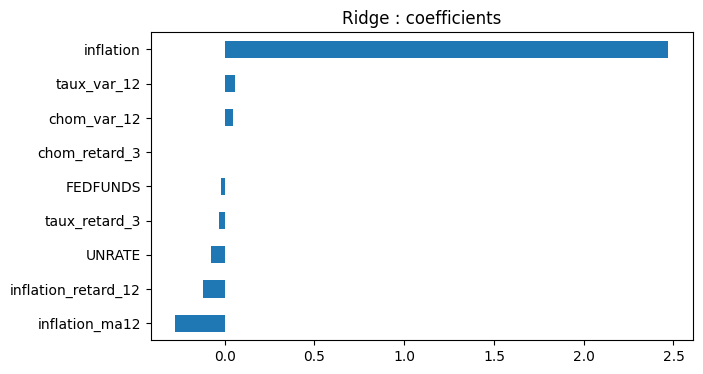

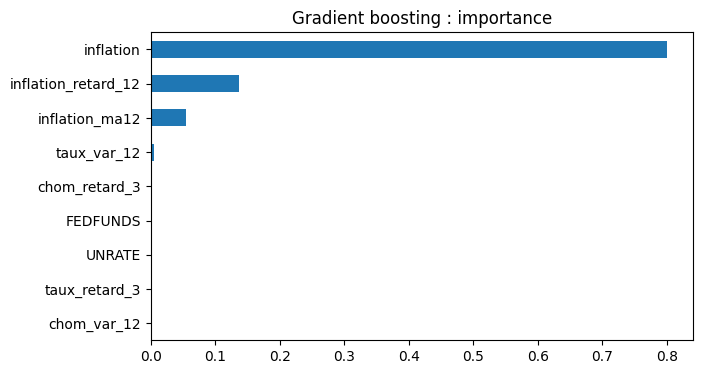

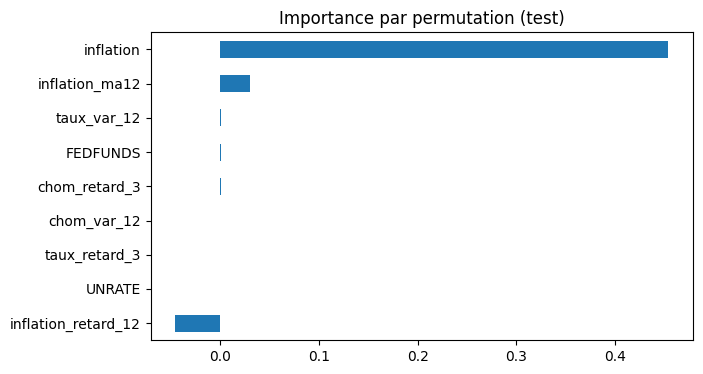

In [157]:
## importance de valeurs

# Coefficients Ridge (variables standardisées, donc comparables)
coefs = pd.Series(gs_ridge.best_estimator_.named_steps["ridge"].coef_, index=features)
coefs.sort_values().plot(kind="barh", figsize=(7, 4), title="Ridge : coefficients")
plt.show()

# Importance du gradient boosting
imp = pd.Series(gs_gb.best_estimator_.feature_importances_, index=features)
imp.sort_values().plot(kind="barh", figsize=(7, 4), title="Gradient boosting : importance")
plt.show()

# Importance par permutation, calculée sur le jeu de test
perm = permutation_importance(gs_gb.best_estimator_, X_test, y_test,
                              n_repeats=20, random_state=0,
                              scoring="neg_root_mean_squared_error")
pd.Series(perm.importances_mean, index=features).sort_values().plot(
    kind="barh", figsize=(7, 4), title="Importance par permutation (test)")
plt.show()

In [158]:
## Analyse de la période 2021-2022

masque = (y_test.index < "2020-01-01")
for nom, pred in [("Référence", pred_ref), ("Ridge", pred_ridge), ("GB", pred_gb)]:
    r_avant = np.sqrt(mean_squared_error(y_test[masque], pd.Series(pred, index=y_test.index)[masque]))
    r_apres = np.sqrt(mean_squared_error(y_test[~masque], pd.Series(pred, index=y_test.index)[~masque]))
    print(f"{nom:10s} RMSE avant 2020 : {r_avant:.3f} | à partir de 2020 : {r_apres:.3f}")

Référence  RMSE avant 2020 : 0.852 | à partir de 2020 : 3.010
Ridge      RMSE avant 2020 : 0.972 | à partir de 2020 : 2.553
GB         RMSE avant 2020 : 0.914 | à partir de 2020 : 3.407
